# CyberTransformers V1.1 — Clasificador Transformer desde (casi) cero
**Curso NLP | Universidad ICESI | Mini-proyecto: clasificación de texto con Transformers**

**Pregunta de investigación:** ¿Cómo varía la clasificación de mensajes técnicos entre TF-IDF + Regresión Logística y un encoder Transformer entrenado desde cero? ¿Qué ocurre al cambiar la codificación posicional?

**Caso original**: cuatro categorías públicas de `20 Newsgroups`: hardware PC, hardware Mac, X Window y criptografía. No se reutilizan las noticias españolas de la guía. El trabajo sigue las etapas de la guía `1-transformers-from-scratch.ipynb` (tokenización, embeddings, atención, bloque y clasificador), con ajustes de seguridad metodológica y memoria. **No es un BERT preentrenado**.

**Estado de resultados**: los gráficos y métricas se obtienen al ejecutar este notebook; no se asumen valores. El conjunto de prueba se reserva para la evaluación final.

## 0. Preparación de Colab
Seleccionar **T4 GPU**, preferiblemente en un runtime nuevo. Solo se instalan bibliotecas imprescindibles. No instalamos LangChain, Ollama, Gradio ni Lightning. El `torch` suministrado por Colab se conserva.

In [ ]:
%pip -q install "scikit-learn>=1.4,<2" "pandas>=2.1,<3" "matplotlib>=3.7" "tokenizers>=0.19,<1" "tqdm>=4.66"

In [ ]:
import os, random, time, json, copy, math, pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from tokenizers import Tokenizer, models, pre_tokenizers, trainers, decoders
from tqdm.auto import tqdm
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT=pathlib.Path('/content/cybertransformers_resultados' if pathlib.Path('/content').exists() else 'cybertransformers_resultados');OUT.mkdir(exist_ok=True)
print('PyTorch',torch.__version__, '| device:', device)
if device.type=='cuda': print(torch.cuda.get_device_name(0))

PyTorch 2.11.0+cu130 | device: cuda
Tesla T4


## 1. Datos y análisis exploratorio (EDA)
Se carga el conjunto de entrenamiento y el de prueba **oficiales**. Se eliminan cabeceras, pies y citas para reducir fuga de etiquetas por metadatos. De los datos de entrenamiento se separa validación estratificada; el conjunto `test` original se usa una sola vez para la comparación final. Los mensajes públicos pueden contener ruido y contenido histórico.

In [ ]:
CATS=['comp.sys.ibm.pc.hardware','comp.sys.mac.hardware','comp.windows.x','sci.crypt']
NAMES=['Hardware PC','Hardware Mac','X Window','Criptografía']
tr=fetch_20newsgroups(subset='train',categories=CATS,remove=('headers','footers','quotes'),shuffle=True,random_state=SEED)
te=fetch_20newsgroups(subset='test',categories=CATS,remove=('headers','footers','quotes'),shuffle=False)
raw_train=pd.DataFrame({'texto':tr.data,'y':tr.target})
raw_test=pd.DataFrame({'texto':te.data,'y':te.target})
def limpiar(x):return ' '.join(str(x).split())
for frame in (raw_train,raw_test):
    frame['texto']=frame.texto.map(limpiar)
    frame.drop(frame[frame.texto.str.len()<25].index,inplace=True)
    frame.reset_index(drop=True,inplace=True)
train_df,val_df=train_test_split(raw_train,test_size=.2,random_state=SEED,stratify=raw_train.y)
train_df=train_df.reset_index(drop=True);val_df=val_df.reset_index(drop=True)
# límites por costo en Colab; mantener proporciones de clase y documentar el muestreo
MAX_TRAIN=2400;MAX_VAL=500;MAX_TEST=650
def estrat_sub(df,n):
    if len(df)<=n:return df.reset_index(drop=True)
    keep,_=train_test_split(df,train_size=n,random_state=SEED,stratify=df.y)
    return keep.reset_index(drop=True)
train_df=estrat_sub(train_df,MAX_TRAIN);val_df=estrat_sub(val_df,MAX_VAL);test_df=estrat_sub(raw_test,MAX_TEST)
for df in (train_df,val_df,test_df):
    df['palabras']=df.texto.str.split().str.len()
    df['clase']=df.y.map(dict(enumerate(NAMES)))
print('Tamaños:',len(train_df),len(val_df),len(test_df))
display(train_df[['texto','clase','palabras']].head(3))

Tamaños: 1836 460 650


,texto,clase,palabras
0,Without getting into the *really* *thorny* que...,Criptografía,155
1,I'm getting a sad Mac icon on a black screen w...,Hardware Mac,30
2,Here's what I (think) have figured out. All I ...,X Window,121


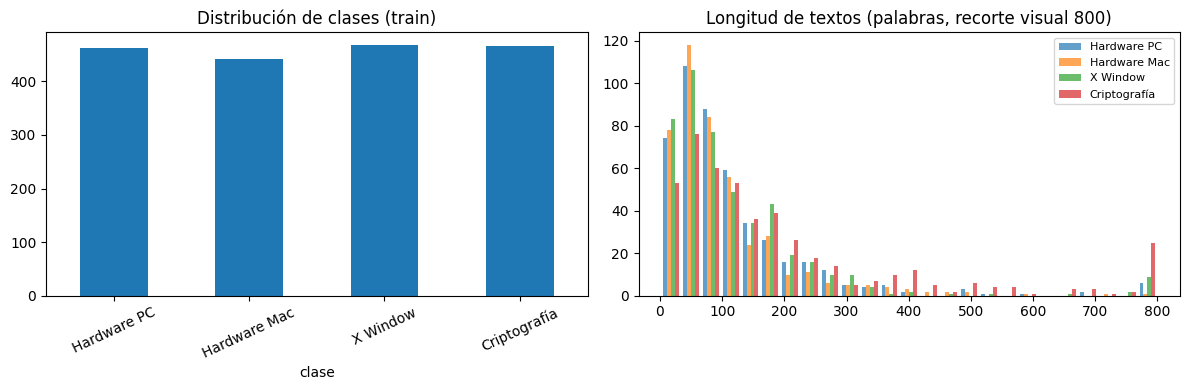

count    1836.0
mean      188.5
std       608.7
min         2.0
50%        87.0
75%       168.0
90%       278.5
95%       414.2
max      9365.0
Name: palabras, dtype: float64


In [ ]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
train_df.clase.value_counts().reindex(NAMES).plot.bar(ax=axs[0]);axs[0].set_title('Distribución de clases (train)');axs[0].tick_params(axis='x',rotation=25)
axs[1].hist([train_df.loc[train_df.y==i,'palabras'].clip(upper=800) for i in range(4)],bins=25,label=NAMES,alpha=.7)
axs[1].set_title('Longitud de textos (palabras, recorte visual 800)');axs[1].legend(fontsize=8)
plt.tight_layout();plt.savefig(OUT/'eda_clases_longitudes.png',dpi=150);plt.show()
print(train_df.palabras.describe(percentiles=[.5,.75,.9,.95]).round(1))

## 2. Baseline TF-IDF + regresión logística
La línea base es simple, barata y difícil de superar en corpus pequeños. El vectorizador se ajusta **solo** sobre entrenamiento.

In [ ]:
tic=time.perf_counter()
vec=TfidfVectorizer(max_features=15000,ngram_range=(1,2),min_df=2,sublinear_tf=True,stop_words='english')
Xtr=vec.fit_transform(train_df.texto);Xv=vec.transform(val_df.texto)
clf=LogisticRegression(max_iter=600,random_state=SEED)
clf.fit(Xtr,train_df.y)
val_pred=clf.predict(Xv)
print('TF-IDF validation Macro-F1:',round(f1_score(val_df.y,val_pred,average='macro'),4),'| segundos:',round(time.perf_counter()-tic,2))

TF-IDF validation Macro-F1: 0.8818 | segundos: 1.79


## 3. Tokenizador subword entrenado únicamente con train
La guía entrena un tokenizador a partir de GPT-2; aquí empleamos la biblioteca `tokenizers` para entrenar **Byte-level BPE desde cero** y evitar instalaciones adicionales. Reservamos `[PAD]`, `[UNK]`; `[PAD]` tiene índice 0 y solo se utiliza para completar secuencias. El vocabulario no ve validación ni test.

In [ ]:
tok=Tokenizer(models.BPE(unk_token='[UNK]'))
tok.pre_tokenizer=pre_tokenizers.ByteLevel(add_prefix_space=True)
tok.decoder=decoders.ByteLevel()
tok.train_from_iterator(train_df.texto.tolist(),trainer=trainers.BpeTrainer(vocab_size=6000,min_frequency=2,special_tokens=['[PAD]','[UNK]']),length=len(train_df))
PAD=tok.token_to_id('[PAD]');assert PAD==0
SEQ_LEN=128
sample=tok.encode('Security updates mitigate known vulnerabilities.')
print('Vocabulario:',tok.get_vocab_size(),'| tokens:',sample.tokens,'| ids:',sample.ids)
tok.save(str(OUT/'tokenizer.json'))

Vocabulario: 6000 | tokens: ['ĠSecurity', 'Ġupd', 'ates', 'Ġmit', 'ig', 'ate', 'Ġknown', 'Ġvulner', 'abilities', '.'] | ids: [2908, 2482, 1025, 4858, 229, 247, 1857, 5672, 3059, 15]


In [ ]:
class TextDS(Dataset):
    def __init__(self,df,tokenizer,seq_len):self.df=df;self.tok=tokenizer;self.seq_len=seq_len
    def __len__(self):return len(self.df)
    def __getitem__(self,i):
        row=self.df.iloc[i];ids=self.tok.encode(row.texto).ids[:self.seq_len]
        mask=[1]*len(ids);n=self.seq_len-len(ids)
        return {'ids':torch.tensor(ids+[PAD]*n,dtype=torch.long),'mask':torch.tensor(mask+[0]*n,dtype=torch.bool),'y':torch.tensor(int(row.y),dtype=torch.long)}
BATCH=32
tr_dl=DataLoader(TextDS(train_df,tok,SEQ_LEN),batch_size=BATCH,shuffle=True,num_workers=0)
va_dl=DataLoader(TextDS(val_df,tok,SEQ_LEN),batch_size=64,num_workers=0)
te_dl=DataLoader(TextDS(test_df,tok,SEQ_LEN),batch_size=64,num_workers=0)
batch=next(iter(tr_dl));print({k:v.shape for k,v in batch.items()},'| padding:',int((~batch['mask']).sum()))

{'ids': torch.Size([32, 128]), 'mask': torch.Size([32, 128]), 'y': torch.Size([32])} | padding: 1330


## 4. Positional embeddings
Implementación de la codificación sinusoidal del artículo *Attention Is All You Need*:

\[PE(pos,2i)=\sin(pos/10000^{2i/d}),\quad PE(pos,2i+1)=\cos(pos/10000^{2i/d})\]

Se añade una segunda opción **aprendible** para una ablación controlada.

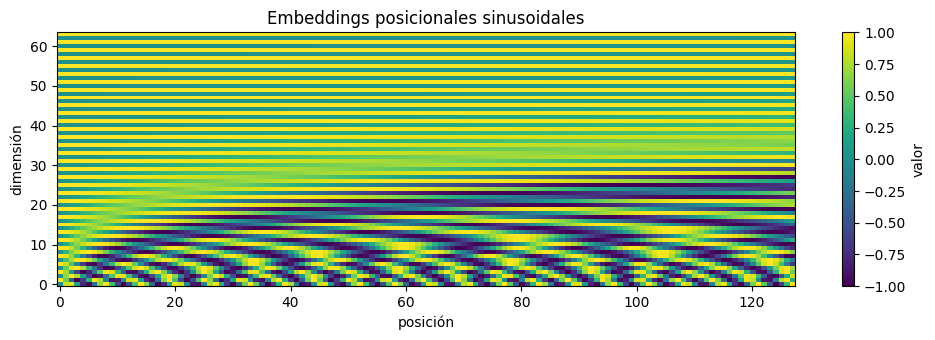

In [ ]:
class PositionalEmbedding(nn.Module):
    def __init__(self,limit,d,kind='sinusoidal'):
        super().__init__();self.kind=kind
        if kind=='aprendible':self.table=nn.Embedding(limit,d)
        else:
            pos=torch.arange(limit,dtype=torch.float32).unsqueeze(1)
            term=torch.exp(torch.arange(0,d,2,dtype=torch.float32)*(-math.log(10000.0)/d))
            pe=torch.zeros(limit,d);pe[:,0::2]=torch.sin(pos*term);pe[:,1::2]=torch.cos(pos*term)
            self.register_buffer('pe',pe)
    def forward(self,x):
        length=x.shape[1]
        return self.table(torch.arange(length,device=x.device))[None,:,:] if self.kind=='aprendible' else self.pe[:length][None,:,:]
pe=PositionalEmbedding(SEQ_LEN,64).pe
plt.figure(figsize=(10,3.5));plt.imshow(pe.T.numpy(),aspect='auto',origin='lower');plt.colorbar(label='valor');plt.xlabel('posición');plt.ylabel('dimensión');plt.title('Embeddings posicionales sinusoidales');plt.tight_layout();plt.savefig(OUT/'positional_embeddings.png',dpi=150);plt.show()

## 5. Self-Attention multicabeza escrita desde cero
Implementamos proyecciones Q, K, V, producto escalado, máscara en claves, Softmax, concatenación de cabezas y proyección final. La máscara evita atender a tokens de padding. La salida se usa con *masked mean pooling*, que evita que el padding influya en la clasificación.

In [ ]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self,d=64,heads=4):
        super().__init__();assert d%heads==0
        self.d=d;self.heads=heads;self.dk=d//heads
        self.qkv=nn.Linear(d,3*d);self.proj=nn.Linear(d,d)
    def forward(self,x,mask,return_attention=False):
        B,L,D=x.shape
        qkv=self.qkv(x).reshape(B,L,3,self.heads,self.dk).permute(2,0,3,1,4)
        q,k,v=qkv[0],qkv[1],qkv[2]
        score=(q@k.transpose(-2,-1))/math.sqrt(self.dk)
        score=score.masked_fill(~mask[:,None,None,:],-1e4)
        a=torch.softmax(score,dim=-1)
        out=(a@v).transpose(1,2).contiguous().reshape(B,L,D)
        out=self.proj(out)
        return (out,a) if return_attention else out
class EncoderBlock(nn.Module):
    def __init__(self,d,heads):
        super().__init__();self.n1=nn.LayerNorm(d);self.attn=MultiHeadSelfAttention(d,heads)
        self.n2=nn.LayerNorm(d);self.ffn=nn.Sequential(nn.Linear(d,4*d),nn.GELU(),nn.Dropout(.1),nn.Linear(4*d,d))
        self.drop=nn.Dropout(.1)
    def forward(self,x,mask):
        x=x+self.drop(self.attn(self.n1(x),mask));x=x+self.drop(self.ffn(self.n2(x)))
        return x
class ScratchClassifier(nn.Module):
    def __init__(self,vocab,limit,d=64,heads=4,depth=2,position='sinusoidal'):
        super().__init__();self.emb=nn.Embedding(vocab,d,padding_idx=PAD)
        self.pos=PositionalEmbedding(limit,d,position);self.blocks=nn.ModuleList([EncoderBlock(d,heads) for _ in range(depth)])
        self.norm=nn.LayerNorm(d);self.head=nn.Linear(d,4)
    def forward(self,ids,mask):
        x=self.emb(ids)+self.pos(ids)
        for layer in self.blocks:x=layer(x,mask)
        x=self.norm(x);m=mask.unsqueeze(-1).to(x.dtype)
        pooled=(x*m).sum(dim=1)/m.sum(dim=1).clamp(min=1)
        return self.head(pooled)
model=ScratchClassifier(tok.get_vocab_size(),SEQ_LEN).to(device)
batch=next(iter(tr_dl));out=model(batch['ids'].to(device),batch['mask'].to(device))
print('Dimensión logits:',out.shape,'| parámetros:',sum(p.numel() for p in model.parameters()))
assert out.shape==(len(batch['y']),4)

Dimensión logits: torch.Size([32, 4]) | parámetros: 484356


## 6. Entrenamiento y validación
Se usa AdamW, *gradient clipping*, dos épocas iniciales y selección por **Macro-F1 de validación**. El conjunto test permanece intacto. Si la GPU es lenta, reducir MAX_TRAIN o EPOCHS, documentándolo.

In [ ]:
@torch.no_grad()
def evaluar(model,loader):
    model.eval();yt,yp,pr=[],[],[]
    for b in loader:
        logits=model(b['ids'].to(device),b['mask'].to(device))
        p=logits.softmax(-1).cpu().numpy()
        yt.extend(b['y'].numpy());yp.extend(p.argmax(1));pr.extend(p)
    return np.array(yt),np.array(yp),np.array(pr)
def entrenar(position='sinusoidal',epochs=2):
    torch.manual_seed(SEED)
    m=ScratchClassifier(tok.get_vocab_size(),SEQ_LEN,d=64,heads=4,depth=2,position=position).to(device)
    opt=torch.optim.AdamW(m.parameters(),lr=7e-4,weight_decay=.01)
    hist=[];best=-1;best_sd=None;start=time.perf_counter()
    for ep in range(epochs):
        m.train();losses=[]
        for b in tqdm(tr_dl,desc=f'{position} época {ep+1}',leave=False):
            opt.zero_grad(set_to_none=True)
            logits=m(b['ids'].to(device),b['mask'].to(device))
            loss=F.cross_entropy(logits,b['y'].to(device));loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(),1.0);opt.step();losses.append(float(loss.item()))
        y,p,_=evaluar(m,va_dl);f1=f1_score(y,p,average='macro')
        hist.append({'modelo':position,'época':ep+1,'loss_train':float(np.mean(losses)),'macro_f1_val':float(f1)})
        print(position,'época',ep+1,'loss',round(np.mean(losses),4),'F1 val',round(f1,4))
        if f1>best:best=f1;best_sd=copy.deepcopy(m.state_dict())
    m.load_state_dict(best_sd);return m,pd.DataFrame(hist),time.perf_counter()-start
EPOCHS=2
model_sin,hist_sin,secs_sin=entrenar('sinusoidal',EPOCHS)

sinusoidal época 1:   0%|          | 0/58 [00:00<?, ?it/s]

sinusoidal época 1 loss 1.3697 F1 val 0.2487


sinusoidal época 2:   0%|          | 0/58 [00:00<?, ?it/s]

sinusoidal época 2 loss 1.2877 F1 val 0.4445


## 7. Ablación de posición
Entrenamos el mismo modelo con embeddings de posición **aprendibles** usando las mismas particiones, seed y épocas. Interpretar el resultado teniendo en cuenta la variabilidad estadística; una repetición no demuestra superioridad universal.

aprendible época 1:   0%|          | 0/58 [00:00<?, ?it/s]

aprendible época 1 loss 1.379 F1 val 0.3236


aprendible época 2:   0%|          | 0/58 [00:00<?, ?it/s]

aprendible época 2 loss 1.3141 F1 val 0.3635


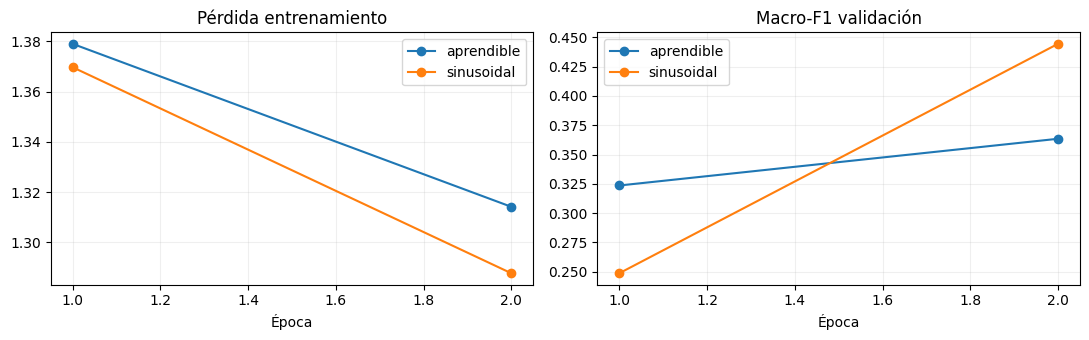

In [ ]:
EJECUTAR_ABLACION=True
if EJECUTAR_ABLACION:
    model_learn,hist_learn,secs_learn=entrenar('aprendible',EPOCHS)
else:
    model_learn=None;hist_learn=pd.DataFrame();secs_learn=float('nan')
hist=pd.concat([hist_sin,hist_learn],ignore_index=True)
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
for nom,g in hist.groupby('modelo'):
    axs[0].plot(g['época'],g.loss_train,marker='o',label=nom)
    axs[1].plot(g['época'],g.macro_f1_val,marker='o',label=nom)
axs[0].set_title('Pérdida entrenamiento');axs[1].set_title('Macro-F1 validación')
for a in axs:a.set_xlabel('Época');a.legend();a.grid(alpha=.2)
plt.tight_layout();plt.savefig(OUT/'curvas_entrenamiento.png',dpi=150);plt.show()

## 8. Evaluación final sobre el conjunto de prueba
Las configuraciones se seleccionan por validación; a continuación se reporta test únicamente una vez. Incluimos TF-IDF, Transformer sinusoidal y, si se ejecutó, Transformer con posición aprendible.

In [ ]:
rows=[];preds={};actual=test_df.y.to_numpy()
t0=time.perf_counter();baseline_pred=clf.predict(vec.transform(test_df.texto));baseline_sec=time.perf_counter()-t0
preds['TF-IDF + LR']=baseline_pred
rows.append({'modelo':'TF-IDF + LR','accuracy':accuracy_score(actual,baseline_pred),'macro_f1':f1_score(actual,baseline_pred,average='macro'),'tiempo_inferencia_s':baseline_sec})
for name,m in [('Transformer sinusoidal',model_sin),('Transformer aprendible',model_learn)]:
    if m is None:continue
    t0=time.perf_counter();y,p,prob=evaluar(m,te_dl);dt=time.perf_counter()-t0
    assert np.array_equal(y,actual)
    preds[name]=p
    rows.append({'modelo':name,'accuracy':accuracy_score(y,p),'macro_f1':f1_score(y,p,average='macro'),'tiempo_inferencia_s':dt})
res=pd.DataFrame(rows).sort_values('macro_f1',ascending=False)
display(res.round(4));res.to_csv(OUT/'comparacion_modelos.csv',index=False);hist.to_csv(OUT/'historial.csv',index=False)

,modelo,accuracy,macro_f1,tiempo_inferencia_s
0,TF-IDF + LR,0.8708,0.8707,0.1047
1,Transformer sinusoidal,0.4400,0.4375,0.7762
2,Transformer aprendible,0.3969,0.3540,0.5593


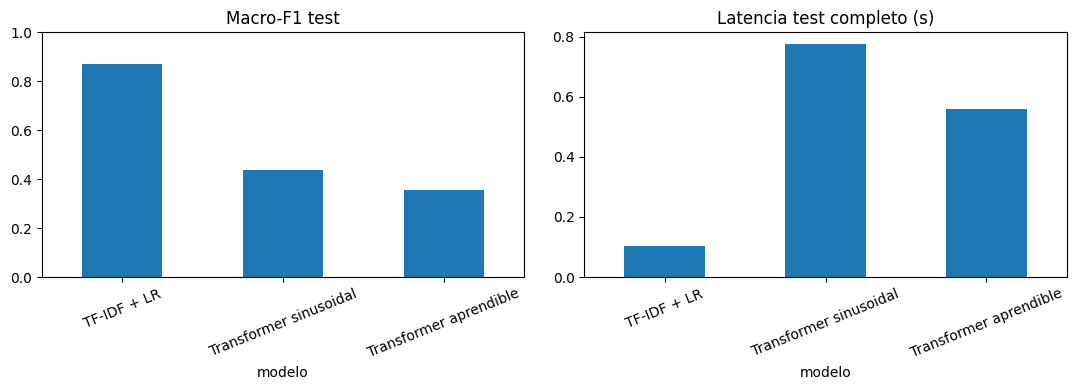

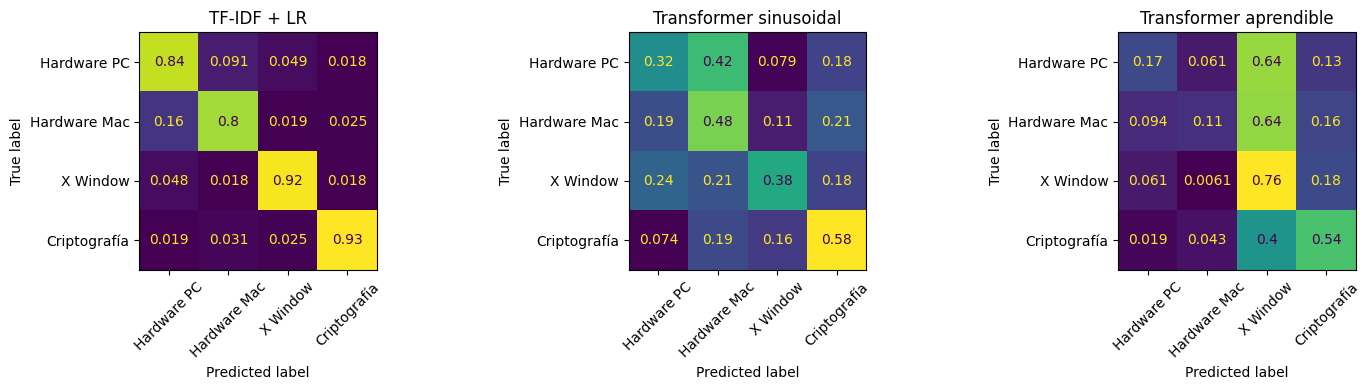

In [ ]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
res.plot.bar(x='modelo',y='macro_f1',ax=axs[0],legend=False);axs[0].set_ylim(0,1);axs[0].set_title('Macro-F1 test')
res.plot.bar(x='modelo',y='tiempo_inferencia_s',ax=axs[1],legend=False);axs[1].set_title('Latencia test completo (s)')
for a in axs:a.tick_params(axis='x',rotation=22)
plt.tight_layout();plt.savefig(OUT/'comparacion_final.png',dpi=150);plt.show()
fig,axs=plt.subplots(1,len(preds),figsize=(5*len(preds),4))
if len(preds)==1:axs=[axs]
for ax,(name,p) in zip(axs,preds.items()):
    ConfusionMatrixDisplay.from_predictions(actual,p,display_labels=NAMES,normalize='true',ax=ax,colorbar=False,xticks_rotation=45)
    ax.set_title(name)
plt.tight_layout();plt.savefig(OUT/'matrices_confusion.png',dpi=150);plt.show()

## 9. Análisis de errores y robustez por longitud
Mostrar casos concretos es indispensable para interpretar qué se confunde. Se comprueba si hay errores sistemáticos en textos cortos y largos.

,texto,clase,pred_clase
27,A friend of mine recently acquired an 8!24 GC ...,Hardware Mac,Hardware PC
31,I will poke around in the U of M archives and ...,Hardware Mac,X Window
41,sherman@lea.csc.ncsu.edu (Chris Sherman) gripe...,X Window,Criptografía
46,GCC and other big programs seemed to crash abo...,Hardware PC,X Window
49,Thank you Andrew. Not only for the firm rebutt...,Criptografía,Hardware Mac
56,I have a small network running in my dorm at s...,Hardware Mac,Hardware PC
64,That's what the pseudo-disclaimer is supposed ...,Hardware Mac,Criptografía
86,"There will always be a zillion lawyers who, if...",X Window,Hardware Mac


,grupo_longitud,n,accuracy
0,<=40,131,0.755725
1,41-100,259,0.884170
2,101-250,207,0.913043
3,>250,53,0.924528


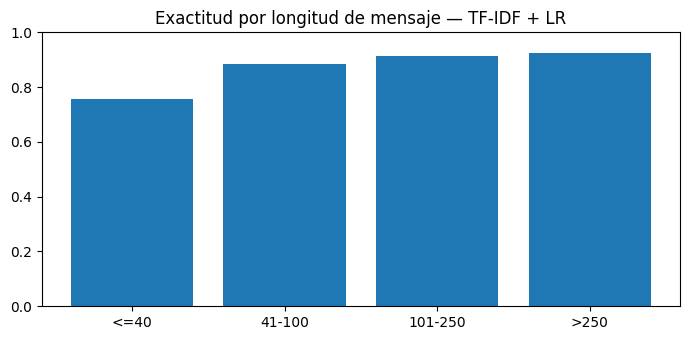

In [ ]:
best_name=res.iloc[0]['modelo'];best_pred=preds[best_name]
err=test_df.copy();err['pred']=best_pred;err['acierto']=(err.y==err.pred)
err['pred_clase']=err.pred.map(dict(enumerate(NAMES)))
display(err.loc[~err.acierto,['texto','clase','pred_clase']].head(8))
err.to_csv(OUT/'predicciones_test.csv',index=False)
err['grupo_longitud']=pd.cut(err.palabras,bins=[0,40,100,250,np.inf],labels=['<=40','41-100','101-250','>250'],include_lowest=True)
by_len=err.groupby('grupo_longitud',observed=True).agg(n=('acierto','size'),accuracy=('acierto','mean')).reset_index()
display(by_len)
fig,ax=plt.subplots(figsize=(7,3.5));ax.bar(by_len.grupo_longitud.astype(str),by_len.accuracy);ax.set_ylim(0,1);ax.set_title('Exactitud por longitud de mensaje — '+best_name);plt.tight_layout();plt.savefig(OUT/'precision_por_longitud.png',dpi=150);plt.show()

## 10. Prueba interactiva y atención
El clasificador es un encoder especializado; no responde como un chatbot. La siguiente función permite introducir una consulta para predecir la clase. La visualización de atención es orientativa: **atención no constituye por sí sola una explicación causal** de la predicción.

In [ ]:
def predecir(texto,modelo=model_sin):
    ids=tok.encode(limpiar(texto)).ids[:SEQ_LEN]
    if not ids:return {'error':'Introduce texto'}
    mask=[1]*len(ids);pads=SEQ_LEN-len(ids)
    with torch.no_grad():
        z=modelo(torch.tensor([ids+[PAD]*pads],device=device),torch.tensor([mask+[0]*pads],device=device,dtype=torch.bool))
        p=z.softmax(-1)[0].cpu().numpy()
    return sorted(zip(NAMES,np.round(p,4).tolist()),key=lambda x:-x[1])
for ejemplo in ['How do I install a new SCSI disk on my PC?', 'Is public key encryption safe for email?']:
    print(ejemplo, '\n', predecir(ejemplo))

How do I install a new SCSI disk on my PC? 
 [('Hardware Mac', 0.5098000168800354), ('Hardware PC', 0.31949999928474426), ('X Window', 0.15800000727176666), ('Criptografía', 0.01269999984651804)]
Is public key encryption safe for email? 
 [('Criptografía', 0.49959999322891235), ('Hardware Mac', 0.18490000069141388), ('Hardware PC', 0.16439999639987946), ('X Window', 0.1509999930858612)]


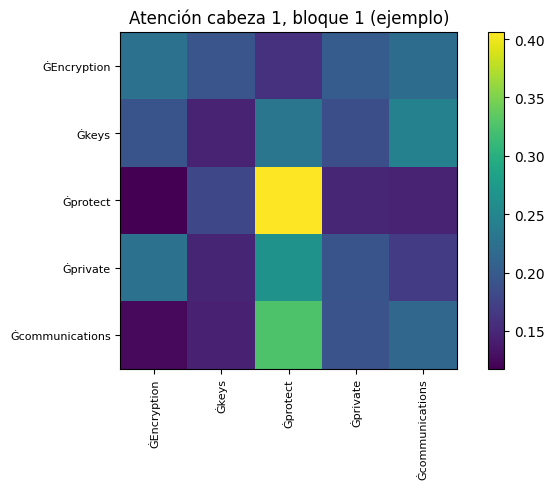

In [ ]:
sample='Encryption keys protect private communications'
ids=tok.encode(sample).ids[:25];mask=torch.ones(1,len(ids),dtype=torch.bool,device=device)
with torch.no_grad():
    emb=model_sin.emb(torch.tensor([ids],device=device))+model_sin.pos(torch.tensor([ids],device=device))
    _,a=model_sin.blocks[0].attn(model_sin.blocks[0].n1(emb),mask,return_attention=True)
weights=a[0,0].cpu().numpy()
labels=tok.encode(sample).tokens[:25]
plt.figure(figsize=(7,5));plt.imshow(weights);plt.xticks(range(len(labels)),labels,rotation=90,fontsize=8);plt.yticks(range(len(labels)),labels,fontsize=8);plt.title('Atención cabeza 1, bloque 1 (ejemplo)');plt.colorbar();plt.tight_layout();plt.savefig(OUT/'atencion_ejemplo.png',dpi=150);plt.show()

## 11. Exportación y discusión
**Responder después de ejecutar:**
1. ¿Qué arquitectura obtuvo mayor Macro-F1 en test? ¿Por cuánto supera o no supera TF-IDF?
2. ¿Cambió la pérdida o la Macro-F1 al sustituir posición sinusoidal por aprendible?
3. ¿Qué categorías muestran más confusión y qué mensajes concretos la originan?
4. ¿Los resultados podrían estar influidos por tamaño muestral, truncamiento, inglés técnico o ruido histórico?
5. ¿La atención observada es coherente con los tokens del mensaje? Evitar interpretaciones causales.

**Límites:** Entrenar desde cero con unas pocas miles de muestras no equivale a preentrenar BERT. El baseline puede superar el Transformer pequeño. La evaluación sobre 20 Newsgroups es académica, no certifica desempeño en incidentes reales.

In [ ]:
import zipfile
with zipfile.ZipFile(OUT.parent/'CyberTransformers_V1_1_Resultados.zip','w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.iterdir():
        if p.is_file():z.write(p,arcname=p.name)
print('Resultados:',OUT.parent/'CyberTransformers_V1_1_Resultados.zip')

## Referencias
- Guía académica: `1-transformers-from-scratch.ipynb` (curso NLP ICESI), usada como referencia estructural.
- Vaswani et al. (2017), *Attention Is All You Need*. https://arxiv.org/abs/1706.03762
- Scikit-learn, *20 Newsgroups*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html
- Hugging Face Tokenizers. https://huggingface.co/docs/tokenizers/index

**Comparación con V1:** V1 ajustaba DistilBERT y ELECTRA preentrenados; esta V1.1 implementa atención, embeddings y bloques Transformer desde cero como en la guía. Son experimentos complementarios, no equivalentes.